# 01 — Dataset exploration (NeuroVision, Phase 1–2)
Runtime → Change runtime type → **GPU** (needed later; harmless now).
Educational prototype, not a clinical diagnostic system.

1. Setup: download the dataset from Kaggle

In [ ]:
# ---- EDIT THIS: your private Kaggle dataset, "username/slug" from its page URL ----
KAGGLE_DATASET = "sainibharat10/neurovision-brain-mri"
# ------------------------------------------------------------------------------------
import os, glob, shutil, zipfile
DATA, ART = "/content/data", "/content/artifacts"     # local disk; download ART files before session ends
os.makedirs(ART, exist_ok=True)

!pip -q install kagglehub
import kagglehub

def find_root(p):
    hits = glob.glob(f"{p}/**/train", recursive=True)
    return os.path.dirname(hits[0]) if hits else None

if not os.path.isdir(f"{DATA}/train"):
    assert "YOUR_USERNAME" not in KAGGLE_DATASET, "Edit KAGGLE_DATASET first"
    try:
        path = kagglehub.dataset_download(KAGGLE_DATASET)
    except Exception:
        kagglehub.login()                              # paste your Kaggle API token
        path = kagglehub.dataset_download(KAGGLE_DATASET)
    root = find_root(path)
    if root is None:                                   # data came as (nested) zip files
        for z in glob.glob(f"{path}/**/*.zip", recursive=True):
            zipfile.ZipFile(z).extractall("/content/_raw")
        for z in glob.glob("/content/_raw/**/*.zip", recursive=True):
            zipfile.ZipFile(z).extractall("/content/_raw")
        root = find_root("/content/_raw")
    assert root, "train/ folder not found in the downloaded data"
    shutil.copytree(root, DATA, dirs_exist_ok=True)

print(sorted(os.listdir(DATA)))    # expect: test, train, val (+ README/csv/png)

100%|██████████| 107M/107M [00:01<00:00, 92.2MB/s]

Extracting files...


['test', 'train', 'val']


In [ ]:
!pip -q install imagehash
import os, json, hashlib, collections
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
DATA = "/content/data"
SPLITS = ["train", "val", "test"]
CLASSES = sorted(os.listdir(f"{DATA}/train"))
print(CLASSES)

['glioma', 'meningioma', 'no_tumor', 'pituitary']


## 2. Class counts per split

split,train,val,test,total
cls,,,,
glioma,1534,329,328,2191
meningioma,1035,222,221,1478
no_tumor,551,118,118,787
pituitary,1040,223,222,1485


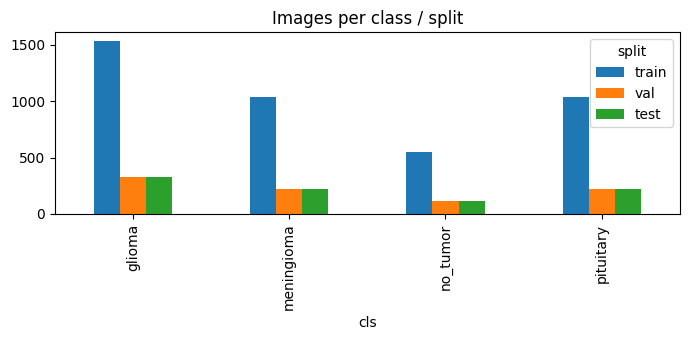

In [ ]:
rows = []
for s in SPLITS:
    for c in CLASSES:
        d = f"{DATA}/{s}/{c}"
        for f in os.listdir(d):
            rows.append((s, c, os.path.join(d, f)))
df = pd.DataFrame(rows, columns=["split", "cls", "path"])
counts = df.pivot_table(index="cls", columns="split", values="path", aggfunc="count")[SPLITS]
counts["total"] = counts.sum(axis=1)
display(counts)
counts[SPLITS].plot(kind="bar", figsize=(7, 3.5), title="Images per class / split")
plt.tight_layout(); plt.show()

## 3. Sample grid

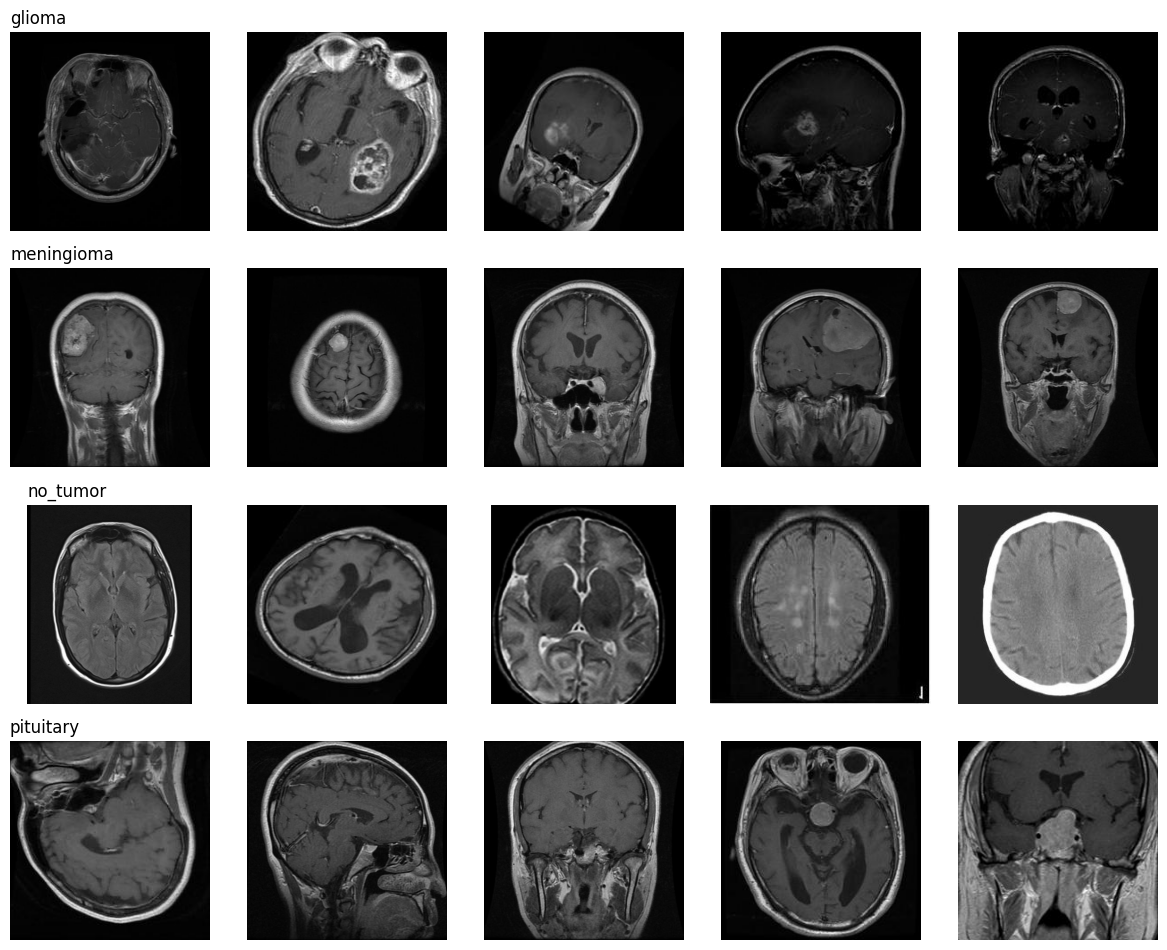

In [ ]:
fig, ax = plt.subplots(len(CLASSES), 5, figsize=(12, 2.4 * len(CLASSES)))
for i, c in enumerate(CLASSES):
    for j, p in enumerate(df[(df.split == "train") & (df.cls == c)].sample(5, random_state=0).path):
        ax[i, j].imshow(Image.open(p).convert("RGB")); ax[i, j].axis("off")
    ax[i, 0].set_title(c, loc="left")
plt.tight_layout(); plt.show()

## 4. Sizes, color modes, corrupt files, exact duplicates

In [ ]:
sizes, modes, bad, md5 = collections.Counter(), collections.Counter(), [], collections.defaultdict(list)
for r in df.itertuples():
    try:
        with Image.open(r.path) as im:
            sizes[im.size] += 1; modes[im.mode] += 1
        md5[hashlib.md5(open(r.path, "rb").read()).hexdigest()].append(r)
    except Exception:
        bad.append(r.path)
print("corrupt:", len(bad), "| modes:", dict(modes))
print("distinct sizes:", len(sizes), "| top:", sizes.most_common(5))
dups = [g for g in md5.values() if len(g) > 1]
print("exact-duplicate groups:", len(dups), "| across splits:", sum(len({x.split for x in g}) > 1 for g in dups))

corrupt: 0 | modes: {'RGB': 4138, 'L': 1800, 'RGBA': 3}
distinct sizes: 349 | top: [((512, 512), 3297), ((224, 224), 1958), ((225, 225), 73), ((236, 236), 27), ((256, 256), 22)]
exact-duplicate groups: 0 | across splits: 0


## 5. Near-duplicate / label-conflict check
README claims phash distance ≤ 5 pairs were removed, but ~22 pairs remain; 11 cross splits and all have *different* labels. Look at them.

pairs with phash distance <= 5: 22 | cross-split: 11 | different class: 22


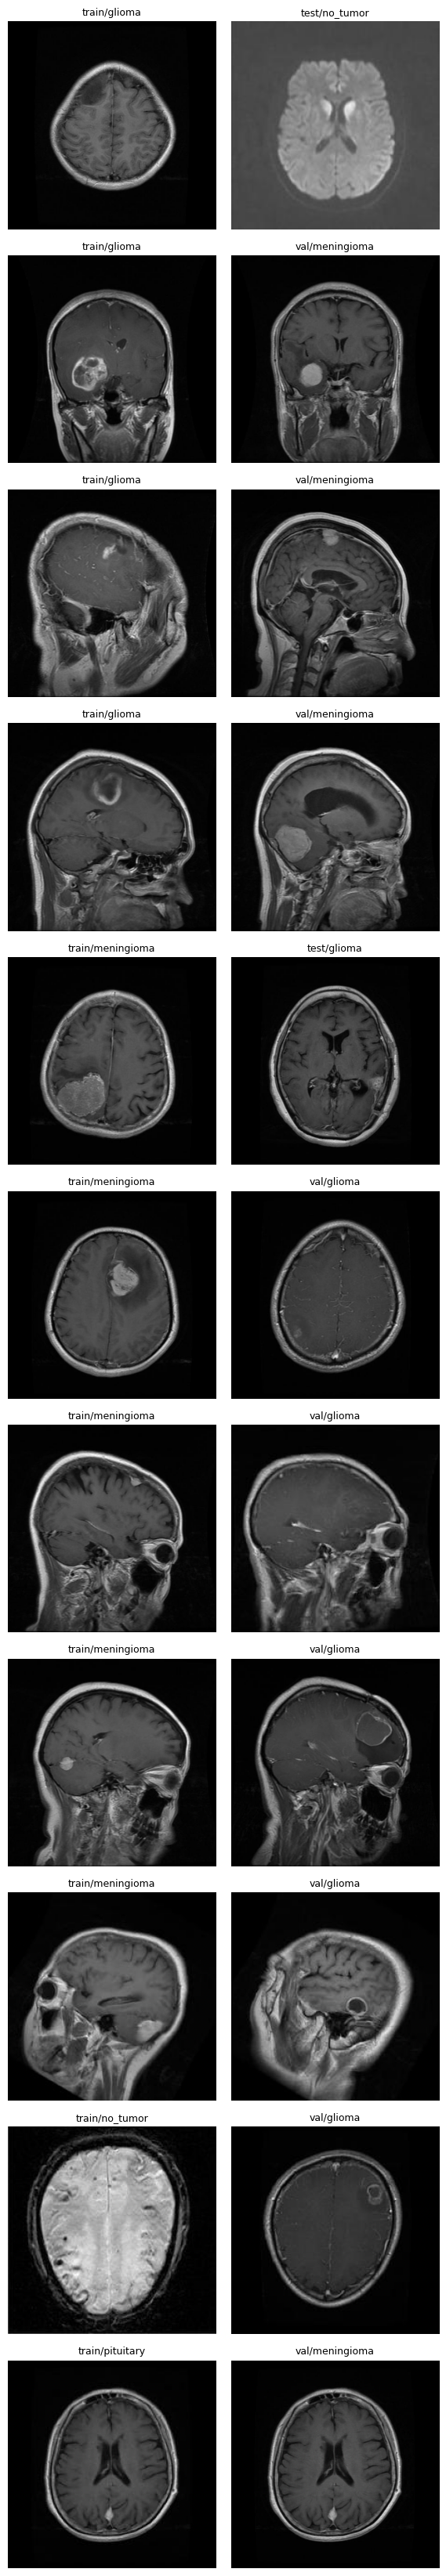

In [ ]:
import imagehash
H = np.array([imagehash.phash(Image.open(p).convert("L")).hash.flatten() for p in df.path], dtype=np.int32)
D = H.shape[1] - (H @ H.T + (1 - H) @ (1 - H).T)
np.fill_diagonal(D, 99)
i, j = np.where(np.triu(D <= 5, 1))
pairs = [(a, b) for a, b in zip(i, j)]
print("pairs with phash distance <= 5:", len(pairs),
      "| cross-split:", sum(df.split[a] != df.split[b] for a, b in pairs),
      "| different class:", sum(df.cls[a] != df.cls[b] for a, b in pairs))
show = [(a, b) for a, b in pairs if df.split[a] != df.split[b]][:11]
fig, ax = plt.subplots(len(show), 2, figsize=(6, 3 * len(show)))
for r, (a, b) in enumerate(show):
    for k, idx in enumerate((a, b)):
        ax[r, k].imshow(Image.open(df.path[idx]).convert("RGB")); ax[r, k].axis("off")
        ax[r, k].set_title(f"{df.split[idx]}/{df.cls[idx]}", fontsize=9)
plt.tight_layout();
plt.show()

**Decision (fill in after looking):** are these true duplicates with conflicting labels (→ drop them) or just look-alike scans (→ keep)?

## 6. Preprocessing and DataLoaders (reused later by the backend)

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T

IMG = 224
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # ImageNet stats (for pretrained models)

train_tf = T.Compose([
    T.Resize((IMG, IMG)),
    T.RandomRotation(10),
    T.RandomAffine(0, translate=(0.05, 0.05)),
    T.ColorJitter(brightness=0.1, contrast=0.1),
    T.ToTensor(), T.Normalize(MEAN, STD)])
eval_tf = T.Compose([T.Resize((IMG, IMG)), T.ToTensor(), T.Normalize(MEAN, STD)])  # no randomness

class MRIDataset(Dataset):
    def __init__(self, frame, tf):
        self.p, self.tf = frame.path.tolist(), tf
        self.y = [CLASSES.index(c) for c in frame.cls]
    def __len__(self): return len(self.p)
    def __getitem__(self, i):
        return self.tf(Image.open(self.p[i]).convert("RGB")), self.y[i]   # force 3-channel RGB

ds = {s: MRIDataset(df[df.split == s], train_tf if s == "train" else eval_tf) for s in SPLITS}
dl = {s: DataLoader(ds[s], batch_size=32, shuffle=(s == "train"), num_workers=2) for s in SPLITS}
xb, yb = next(iter(dl["train"])); print(xb.shape, yb[:8])

# Class weights for imbalance (inverse frequency, train only)
n = np.bincount(ds["train"].y, minlength=len(CLASSES))
class_weights = torch.tensor(n.sum() / (len(CLASSES) * n), dtype=torch.float32)
print(dict(zip(CLASSES, class_weights.numpy().round(3))))

torch.Size([32, 3, 224, 224]) tensor([3, 0, 2, 0, 3, 2, 1, 3])
{'glioma': np.float32(0.678), 'meningioma': np.float32(1.005), 'no_tumor': np.float32(1.887), 'pituitary': np.float32(1.0)}


In [ ]:
json.dump(CLASSES, open(f"{ART}/class_names.json", "w"))
print("saved class_names.json to", ART, "(order = label index)")

saved class_names.json to /content/artifacts (order = label index)
